# Georeferenced local water inference

This example uses the middle-ranked validation chip from the prior audit. The goal is to verify that a real GeoTIFF can be read, scored, and saved with its original map coordinates. It is not a new model evaluation.

Inputs must be two-band Sentinel-1 VV/VH in **dB** and exactly 512×512 pixels; explicit band indices can select these bands from a larger band stack. Linear radar power must be converted before use. The tool cannot infer or verify physical units from pixel values alone.

Outputs: `water_mask.tif` (0 dry, 1 water, 255 no-data), `water_score.tif` (0–1 sigmoid score, -9999 no-data), and `prediction.json` recording provenance. A sigmoid score has not been established as calibrated flood probability. Permanent water remains included.

Pixels masked by the source raster or non-finite in either input band are filled with the normalised mean during inference and marked no-data in outputs. This explicit deployment policy differs from the original label-only benchmark mask. Missing context may also affect nearby valid predictions.

In [1]:
import os
import sys
from pathlib import Path

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))
# Set SEN1FLOODS11_ROOT to use a different local dataset location.
root = Path(os.environ.get("SEN1FLOODS11_ROOT", str(Path.home() / ".cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11")))
assert (root / "splits/flood_test_data.csv").is_file(), f"Dataset not found: {root}"
print("Dataset:", root)


Dataset: /Users/mac/.cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11


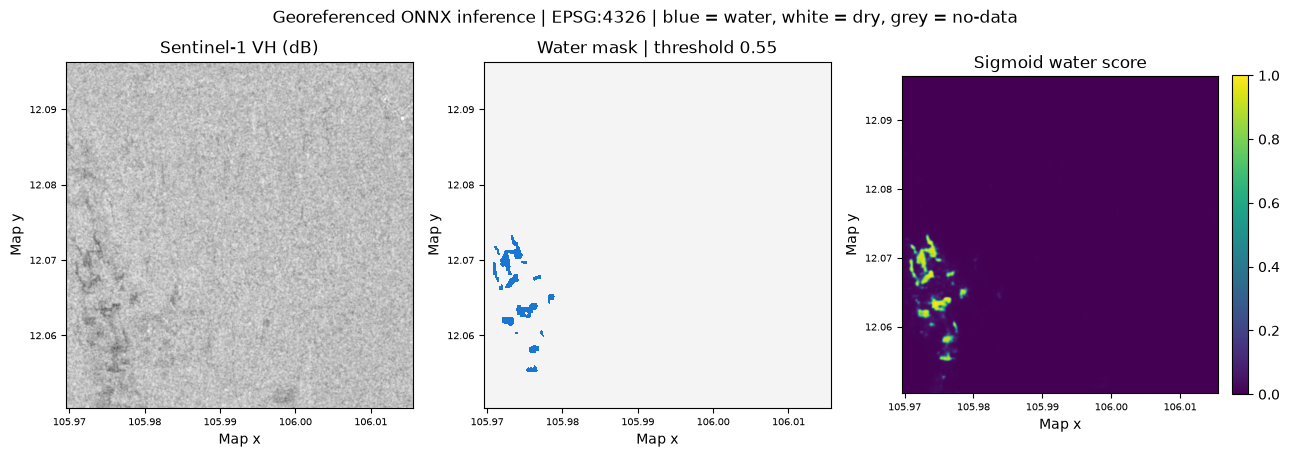

{
  "input": "/Users/mac/.cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11/S1Hand/Mekong_1413877_S1Hand.tif",
  "input_sha256": "eff3ae4d82f730563e6dc310e0d7df1e2e7a6f9d515dd48b89e12e64cfa5d915",
  "model_sha256": "73fb31bbf88120a8f1e1cee20fd7c8b7f78add716a1954afaaa213f1e5bcdb08",
  "config_sha256": "20004b9d9c766572eb0adddf0b30fd1323c9326bf058494a6d236e58bfba208e",
  "vv_band": 1,
  "vh_band": 2,
  "assumed_units": "dB",
  "threshold": 0.55,
  "crs": "EPSG:4326",
  "transform": [
    8.983152841195215e-05,
    0.0,
    105.96958282810253,
    0.0,
    -8.983152841195215e-05,
    12.096354289839828,
    0.0,
    0.0,
    1.0
  ],
  "valid_pixels": 262144,
  "nodata_pixels": 0,
  "predicted_water_pixels": 2220,
  "input_policy": "Finite pixels unmasked in both input bands; other pixels filled with normalised mean for inference and marked no-data in outputs",
  "output_scope": "Water segmentation; permanent water has not been removed"
}


In [2]:
import json
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from floodrisk.deploy.predict import predict

export = PROJECT / "reports/m1-s1-kaggle-365653491/onnx_fp32"
out = PROJECT / "reports/m1-s1-kaggle-365653491/geotiff_demo/mekong"
input_path = root / "S1Hand/Mekong_1413877_S1Hand.tif"
# Preserve an existing run. Use a different output directory for new predictions.
if not out.exists():
    predict(input_path, export / "m1_s1_fp32.onnx", export / "inference_config.json", out)
with rasterio.open(input_path) as src:
    vh = src.read(2)
    bounds = src.bounds
    extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]
    crs = src.crs
    transform = src.transform
with rasterio.open(out / "water_mask.tif") as src:
    assert src.crs == crs and src.transform == transform
    mask = src.read(1, masked=True)
with rasterio.open(out / "water_score.tif") as src:
    assert src.crs == crs and src.transform == transform
    score = src.read(1, masked=True)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(vh, cmap="gray", vmin=-42, vmax=-5, extent=extent)
axes[0].set_title("Sentinel-1 VH (dB)")
cmap = ListedColormap(["#f4f4f4", "#1976d2"])
cmap.set_bad("#bcbcbc")
axes[1].imshow(mask, cmap=cmap, vmin=0, vmax=1, extent=extent, interpolation="nearest")
axes[1].set_title("Water mask | threshold 0.55")
img = axes[2].imshow(score, cmap="viridis", vmin=0, vmax=1, extent=extent)
axes[2].set_title("Sigmoid water score")
fig.colorbar(img, ax=axes[2], fraction=0.046, pad=0.04)
for ax in axes:
    ax.set_xlabel("Map x"); ax.set_ylabel("Map y")
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(labelsize=7)
fig.suptitle(f"Georeferenced ONNX inference | {crs} | blue = water, white = dry, grey = no-data")
fig.tight_layout()
fig.savefig(out / "georeferenced_prediction.png", dpi=150, bbox_inches="tight")
plt.show();plt.close(fig)
print(json.dumps(json.loads((out / "prediction.json").read_text()), indent=2))
